In [12]:
# You must run this code and use this dataset for all questions
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
num_students = 50

# Student data
student_ids = np.arange(201, 201 + num_students)
student_ages = np.random.randint(15, 22, num_students)
student_scores = np.random.randint(40, 100, num_students)
student_attendance = np.random.randint(60, 100, num_students)  # percentage

departments_list = [
    "Science",
    "Commerce",
    "Arts",
    "Computer Science",
    "Mathematics",
    "English",
    "Physics",
    "Chemistry",
    "Biology",
    "Economics"
]

student_departments = np.random.choice(departments_list, num_students)

grade_conditions = [
    student_scores >= 80,
    (student_scores >= 65) & (student_scores < 80),
    (student_scores >= 50) & (student_scores < 65),
    student_scores < 50
]
grade_values = ["A", "B", "C", "F"]
student_grades = np.select(grade_conditions, grade_values, default="F")

# Create DataFrame
data = pd.DataFrame({
    "student_id": student_ids,
    "student_age": student_ages,
    "score": student_scores,
    "attendance": student_attendance,
    "department": student_departments,
    "grade": student_grades
})

# Save dataset
data.to_csv("school_data.csv", index=False)

# Question 01: [ Marks 10 ]

Use NumPy arrays from the score and attendance columns. Print both arrays and display:

* Data type
* Number of dimensions
* Shape
* Total number of elements

In [18]:
import numpy as np
np.array(data)
print(np.array(data.head()))

[[201 21 76 73 'Physics' 'B']
 [202 18 90 82 'Physics' 'A']
 [203 19 46 99 'Biology' 'F']
 [204 21 60 80 'Economics' 'C']
 [205 17 48 75 'Economics' 'F']]


In [13]:
print(data.dtypes)
print(data.ndim)
print(data.shape)
print(data.size)

student_id     int64
student_age    int64
score          int64
attendance     int64
department       str
grade            str
dtype: object
2
(50, 6)
300


In [14]:
print("max score" ,data.score.max(axis=0))
print("min score" ,data.score.min())
print("avg score" ,data.score.mean())
print("avg attendance" ,data.attendance.mean())

 
condition = data.score > data.score.mean()
filter_std = data[condition]
print("Greater than average score:")
print(filter_std)

filter_array = np.array(filter_std.score)
print("New Array:", filter_array)

max score 99
min score 41
avg score 67.3
avg attendance 79.58
Greater than average score:
    student_id  student_age  score  attendance        department grade
0          201           21     76          73           Physics     B
1          202           18     90          82           Physics     A
5          206           19     78          77              Arts     B
9          210           17     99          88  Computer Science     A
11         212           17     89          60           Physics     A
12         213           17     97          84           Physics     A
15         216           17     92          83              Arts     A
19         220           18     86          70           Biology     A
20         221           20     99          76       Mathematics     A
22         223           16     83          94  Computer Science     A
24         225           19     86          92           Physics     A
25         226           15     74          64           B

In [15]:
df = pd.read_csv("school_data.csv")
print(df.head(3))
print(df.info())
print(df.describe())
print(df['student_id'], df['student_age'] , df['department'] , df['grade'])
new_std = df[(df['student_age'] > 16) & (df['student_age'] < 20)]
new_std.sort_values('student_id' , ascending=True).tail(3)

   student_id  student_age  score  attendance department grade
0         201           21     76          73    Physics     B
1         202           18     90          82    Physics     A
2         203           19     46          99    Biology     F
<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   student_id   50 non-null     int64
 1   student_age  50 non-null     int64
 2   score        50 non-null     int64
 3   attendance   50 non-null     int64
 4   department   50 non-null     str  
 5   grade        50 non-null     str  
dtypes: int64(4), str(2)
memory usage: 2.5 KB
None
       student_id  student_age      score  attendance
count    50.00000    50.000000  50.000000   50.000000
mean    225.50000    18.280000  67.300000   79.580000
std      14.57738     1.852081  18.248008   12.163998
min     201.00000    15.000000  41.000000   60.000000
25%     213.2500

,student_id,student_age,score,attendance,department,grade
45,246,18,53,73,Biology,C
47,248,18,87,60,Science,A
49,250,17,47,85,Economics,F


Question 04: [ Marks 10 ]
Using .loc:

Increase the score by 10% for students in "Computer Science" and "Mathematics" departments
Increase the score by 5% for all other departments
Cap the score at 100 (no score should exceed 100 after the raise)
Then print a DataFrame that includes:

student_id, department, previous_score, new_score, score_increase

In [ ]:

df["score"] = df["score"].astype(float)


df["previous_score"] = df["score"]


condition = df["department"].isin(["Computer Science", "Mathematics"])

df.loc[condition, "score"] *= 1.10


df.loc[~condition, "score"] *= 1.05

df["score"] = df["score"].clip(upper=100)


df["score_increase"] = df["score"] - df["previous_score"]


result = df[[
    "student_id",
    "department",
    "previous_score",
    "score",
    "score_increase"
]].rename(columns={"score": "new_score"})

print(result)

    student_id        department  previous_score  new_score  score_increase
0          201           Physics            76.0      79.80            3.80
1          202           Physics            90.0      94.50            4.50
2          203           Biology            46.0      48.30            2.30
3          204         Economics            60.0      63.00            3.00
4          205         Economics            48.0      50.40            2.40
5          206              Arts            78.0      81.90            3.90
6          207           Physics            57.0      59.85            2.85
7          208           Science            43.0      45.15            2.15
8          209  Computer Science            64.0      70.40            6.40
9          210  Computer Science            99.0     100.00            1.00
10         211       Mathematics            53.0      58.30            5.30
11         212           Physics            89.0      93.45            4.45
12         2

Question 05: [ Marks 10 ]
Using Matplotlib, create a bar chart that shows the average score per department.

X-axis: Department names
Y-axis: Average score
Add a title: "Average Score by Department"
Display the chart

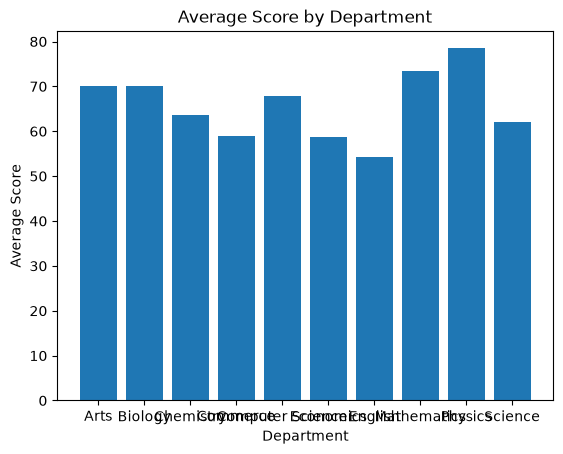

In [17]:
avgScore = df.groupby('department')['score'].mean()
# print(avgScore.index)

plt.bar(avgScore.index, avgScore.values)
plt.xlabel('Department')
plt.ylabel('Average Score')
plt.title('Average Score by Department')
plt.show()

# Question 06: [ Marks 10 ]

Using Matplotlib, create a histogram of the score column.

* Use 10 bins
* Add a title: "Distribution of Student Scores"
* Label X-axis as "Score" and Y-axis as "Number of Students"
* Display the chart

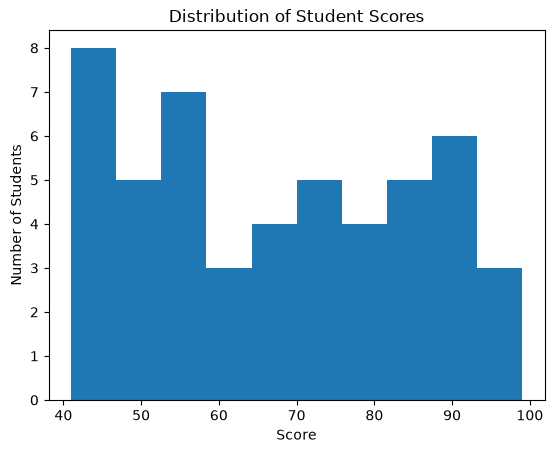

In [18]:
plt.hist(df['score'] , bins=10)
plt.xlabel('Score')
plt.ylabel('Number of Students')
plt.title('Distribution of Student Scores')
plt.show()

Question 07: [ Marks 10 ]
Using Matplotlib, create a scatter plot to visualize the relationship between attendance and score.

X-axis: Attendance (%)
Y-axis: Score
Add a title: "Attendance vs Score"
Label both axes properly
Display the chart

In [ ]:
plt.scatter(df['attendance'] , df['score'])
plt.xlabel('Attendance (%)')
plt.ylabel('Score')
plt.title('Attendance vs Score')
plt.show()

# Question 08: [ Marks 10 ]

Using Seaborn, create a boxplot / barplot that shows the distribution of score across different grade categories.

* X-axis: Grade
* Y-axis: Score
* Add a title: "Score Distribution by Grade"
* Display the chart

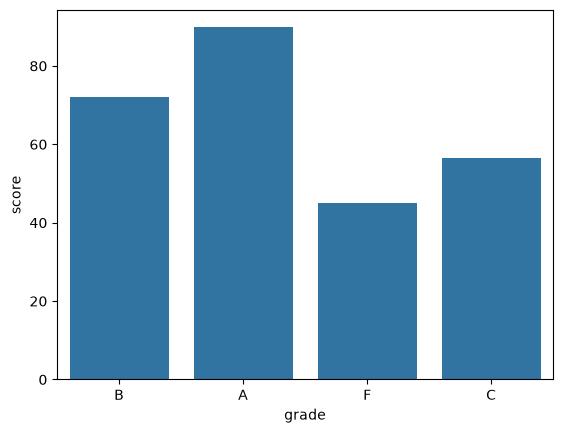

In [ ]:
sns.barplot(data = df, x=df['grade'], y=df['score'], errorbar=None)
plt.title('Score Distribution by Grade')
plt.show()

Using Seaborn, create a countplot showing the number of students in each department.

Add a title: "Number of Students per Department"
Display the chart

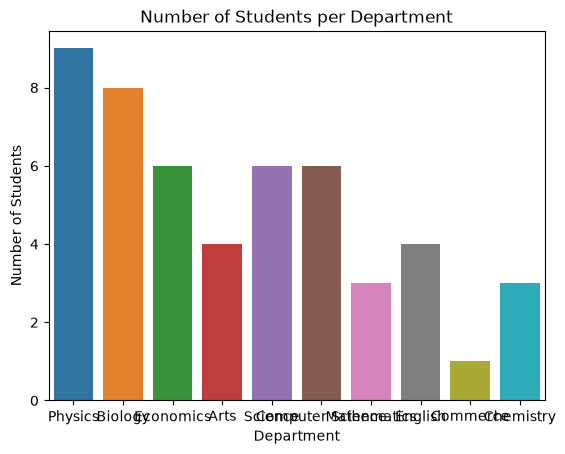

In [25]:


sns.countplot(x=df['department'], data=df , hue=df['department'])

plt.title("Number of Students per Department")
plt.xlabel("Department")
plt.ylabel("Number of Students")

plt.show()

Question 10: [ Marks 10 ]
create a scatter plot showing attendance vs score.

Color the points by department
Add a title: "Attendance vs Score by Department"
Label X-axis as "Attendance (%)" and Y-axis as "Score"
Display the chart

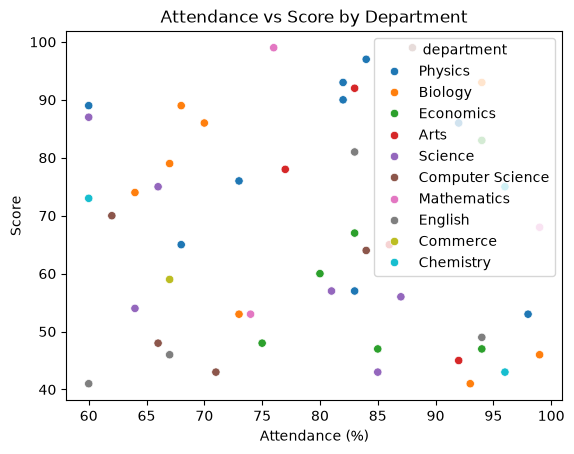

In [24]:
sns.scatterplot(data=df , x='attendance', y='score', hue='department')
plt.title("Attendance vs Score by Department")
plt.xlabel("Attendance (%)")
plt.ylabel("Score")
plt.show()